# Chapitre 2 - Cours 1 : modèle relationnel contre modèle document

Un modèle de données n'est pas un détail d'implémentation : il décide de ce qui sera
facile ou pénible à écrire, et même de la façon dont on pense le problème. Ce premier
cours ouvre le chapitre 2 par la question la plus débattue de ces dernières années :
ranger ses données en **tables** (modèle relationnel) ou en **documents JSON** (modèle
document) ? Il couvre l'introduction du chapitre et la section *Relational Model Versus
Document Model* : *The Birth of NoSQL*, *The Object-Relational Mismatch*, et la
sous-section *Data locality for queries*.

**Plan.**

1. Des modèles empilés en couches.
2. Un demi-siècle de modèles concurrents, et la naissance de NoSQL.
3. Le décalage objet-relationnel : un CV en objets, en tables, en document.
4. Recomposer un CV : plusieurs requêtes, une jointure ou un document ?
5. La localité des données, ses gains et son prix.

In [1]:
import json
import sqlite3
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Des modèles empilés en couches (introduction du chapitre)

Une application superpose plusieurs modèles de données, chacun exprimé dans les termes
du modèle situé juste en dessous :

1. le développeur décrit le monde réel (personnes, commandes, capteurs...) avec des
   **objets** et des structures propres à son application ;
2. pour les stocker, il les traduit dans un **modèle généraliste** : tables
   relationnelles, documents JSON ou XML, sommets et arêtes d'un graphe. C'est le sujet
   de ce chapitre ;
3. les auteurs du moteur de base de données ont choisi comment représenter ces tables
   ou documents en **octets**, en mémoire, sur disque et sur le réseau (chapitre
   3) ;
4. plus bas encore, le matériel représente ces octets par des charges électriques, des
   impulsions lumineuses ou des domaines magnétiques.

Chaque couche **cache la complexité** de celles du dessous derrière un modèle propre.
C'est ce qui permet à des équipes différentes (l'éditeur de la base, les développeurs
qui l'utilisent) de travailler ensemble sans tout connaître les unes des autres.

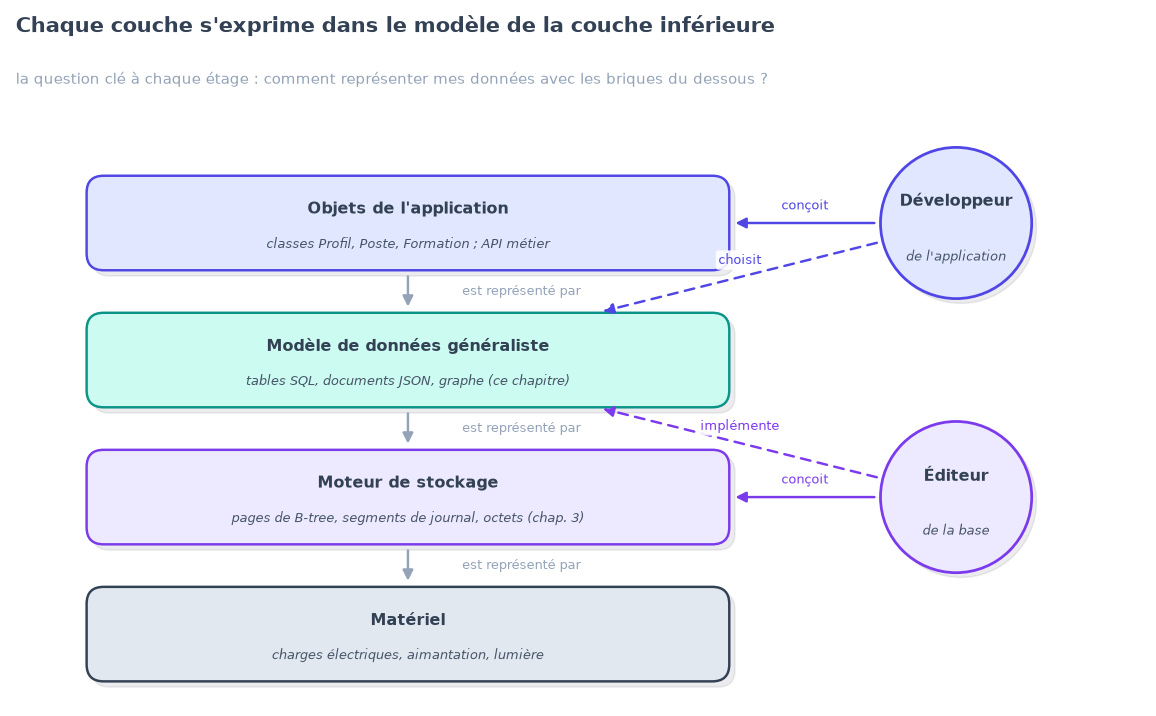

In [2]:
d = Diagram(12, 6.4, title="Chaque couche s'exprime dans le modèle de la couche inférieure",
            subtitle="la question clé à chaque étage : comment représenter mes données avec les briques du dessous ?")
layers = [
    ("app", "Objets de l'application", "classes Profil, Poste, Formation ; API métier", INDIGO),
    ("gen", "Modèle de données généraliste", "tables SQL, documents JSON, graphe (ce chapitre)", TEAL),
    ("eng", "Moteur de stockage", "pages de B-tree, segments de journal, octets (chap. 3)", VIOLET),
    ("hw", "Matériel", "charges électriques, aimantation, lumière", SLATE),
]
for i, (name, txt, sub, col) in enumerate(layers):
    d.box(name, 4.2, 5.1 - 1.45 * i, txt, sub=sub, color=col, w=6.8, h=1.0)
for (a, *_), (b, *_) in zip(layers, layers[1:]):
    d.arrow(a, b, "est représenté par", color=GRAY, label_offset=(1.2, 0))
d.box("dev", 10.0, 5.1, "Développeur", sub="de l'application", kind="user", w=1.6, color=INDIGO)
d.box("ven", 10.0, 2.2, "Éditeur", sub="de la base", kind="user", w=1.6, color=VIOLET)
d.arrow("dev", "app", "conçoit", color=INDIGO)
d.arrow("dev", "gen", "choisit", color=INDIGO, style="dashed")
d.arrow("ven", "gen", "implémente", color=VIOLET, style="dashed")
d.arrow("ven", "eng", "conçoit", color=VIOLET)
d.show()

Le choix du modèle généraliste (couche 2) est le plus lourd de conséquences pour le
développeur : certaines données et certaines requêtes s'expriment naturellement dans un
modèle et maladroitement dans un autre. Le chapitre compare donc les modèles
relationnel, document et graphe, ainsi
que leurs langages de requête.

> **À retenir.** Une application empile des modèles de données ; chacun masque la
> complexité de la couche inférieure. Le modèle généraliste choisi (tables, documents,
> graphe) détermine ce qui sera simple ou difficile à exprimer.

## 2. Un demi-siècle de modèles concurrents (section *Relational Model Versus Document Model*)

Le **modèle relationnel** est proposé par Edgar Codd en 1970 : les données sont des
**relations** (les tables de SQL), ensembles non ordonnés de **n-uplets** (les lignes).
Proposition théorique au départ, dont beaucoup doutaient qu'on sache l'implémenter
efficacement, il s'impose au milieu des années 1980 avec les SGBD relationnels et SQL.

Chaque décennie lui a pourtant opposé un challenger : modèles **hiérarchique** (IMS
d'IBM) et **réseau** (CODASYL) dans les années 1970, bases **objet** à la fin des années
1980, bases **XML** au début des années 2000, puis **NoSQL** à partir de 2009. Aucun n'a
détrôné SQL, qui a fini par absorber leurs idées (types XML, puis JSON).

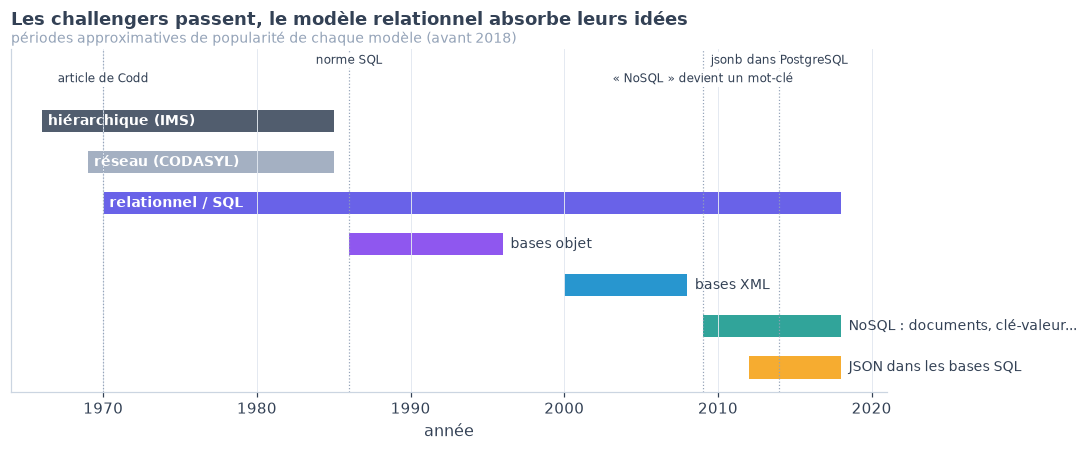

In [3]:
eras = [  # (modèle, début, fin de la période de « battage », couleur)
    ("hiérarchique (IMS)", 1966, 1985, SLATE),
    ("réseau (CODASYL)", 1969, 1985, GRAY),
    ("relationnel / SQL", 1970, 2018, INDIGO),
    ("bases objet", 1986, 1996, VIOLET),
    ("bases XML", 2000, 2008, SKY),
    ("NoSQL : documents, clé-valeur...", 2009, 2018, TEAL),
    ("JSON dans les bases SQL", 2012, 2018, AMBER),
]
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (name, a, b, col) in enumerate(eras):
    ax.barh(i, b - a, left=a, color=col, alpha=0.85, height=0.55)
    if b - a > 14:
        ax.text(a + 0.4, i, name, va="center", ha="left", fontsize=9, color="white", fontweight="bold")
    else:
        ax.text(b + 0.5, i, name, va="center", ha="left", fontsize=9, color=SLATE)
marks = [(1970, "article de Codd"), (1986, "norme SQL"), (2009, "« NoSQL » devient un mot-clé"),
         (2014, "jsonb dans PostgreSQL")]
for k, (yr, txt) in enumerate(marks):
    ax.axvline(yr, color=GRAY, lw=0.8, ls=":")
    ax.text(yr, -0.95 - 0.45 * (k % 2), txt, fontsize=8, color=SLATE, ha="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_yticks([]); ax.set_xlim(1964, 2021); ax.set_ylim(-1.75, len(eras) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("année")
ax.set_title("Les challengers passent, le modèle relationnel absorbe leurs idées")
subtitle(ax, "périodes approximatives de popularité de chaque modèle (avant 2018)")
plt.tight_layout(); plt.show()

### La naissance de NoSQL (section *The Birth of NoSQL*)

Le mot « NoSQL » naît en 2009 comme simple mot-clé d'une rencontre sur les bases
distribuées open source ; il a été relu depuis comme *Not Only SQL*. Le livre distingue
quatre motivations derrière ce mouvement :

- un besoin de **scalabilité** supérieure à celle des bases relationnelles d'alors (très
  gros volumes, débits d'écriture élevés) ;
- une préférence pour les logiciels **libres** plutôt que les bases commerciales ;
- des **requêtes spécialisées** mal servies par le modèle relationnel ;
- la frustration face aux **schémas rigides** et l'envie d'un modèle plus dynamique.

Le livre prédit un avenir de **persistance polyglotte** : une même application combine
une base relationnelle et des magasins non relationnels, chacun pour ce qu'il sait bien
faire.

Le duel qui nous intéresse oppose donc les **tables** et les **documents JSON**. On
reproche aux tables un schéma rigide, on prête aux documents de la souplesse ; la suite
du chapitre examine ces arguments un par un, chiffres à l'appui.

> **À retenir.** Le modèle relationnel domine depuis les années 1980. Ses challengers
> (hiérarchique, réseau, objet, XML, NoSQL) n'ont pas pris sa place, mais ont laissé des
> idées que SQL a absorbées ; l'héritage principal de NoSQL est le modèle document.

## 3. Le décalage objet-relationnel (section *The Object-Relational Mismatch*)

**Le problème.** Le code applicatif manipule des **objets** imbriqués ; une base
relationnelle stocke des **lignes plates** dans des tables. Il faut une couche de
traduction entre les deux, et ce désaccord porte un nom emprunté à l'électronique :
l'*impedance mismatch*. Deux circuits branchés l'un sur l'autre ne transfèrent bien
l'énergie que si leurs impédances concordent ; ici, ce sont deux façons de voir les
données qui concordent mal.

Prenons l'exemple du livre : un **CV** de réseau professionnel. Voici d'abord sa forme
« naturelle » en Python, avec des objets imbriqués.

In [4]:
@dataclass
class Poste:
    job_title: str
    organization: str
    start: int
    end: int | None = None

@dataclass
class Formation:
    school_name: str
    start: int
    end: int

@dataclass
class Profil:
    user_id: int
    first_name: str
    last_name: str
    headline: str
    region_id: str
    positions: list = field(default_factory=list)
    education: list = field(default_factory=list)
    contact_info: dict = field(default_factory=dict)

ines = Profil(42, "Inès", "Martin", "Architecte de données chez Datanet", "fr:69",
              positions=[Poste("Architecte de données", "Datanet", 2014),
                         Poste("Ingénieure logiciel", "Novasoft", 2009, 2014)],
              education=[Formation("INSA Lyon", 2004, 2009)],
              contact_info={"blog": "https://ines.example", "github": "https://github.example/ines"})
ines

Profil(user_id=42, first_name='Inès', last_name='Martin', headline='Architecte de données chez Datanet', region_id='fr:69', positions=[Poste(job_title='Architecte de données', organization='Datanet', start=2014, end=None), Poste(job_title='Ingénieure logiciel', organization='Novasoft', start=2009, end=2014)], education=[Formation(school_name='INSA Lyon', start=2004, end=2009)], contact_info={'blog': 'https://ines.example', 'github': 'https://github.example/ines'})

Dans un **schéma relationnel**, chaque liste devient une table séparée qui pointe vers
`users` par une **clé étrangère** `user_id` : c'est la représentation classique d'une
relation **un-à-plusieurs** (un profil a plusieurs postes, chaque poste appartient à un
seul profil). Les champs uniques (prénom, nom, titre) restent des colonnes de `users`.

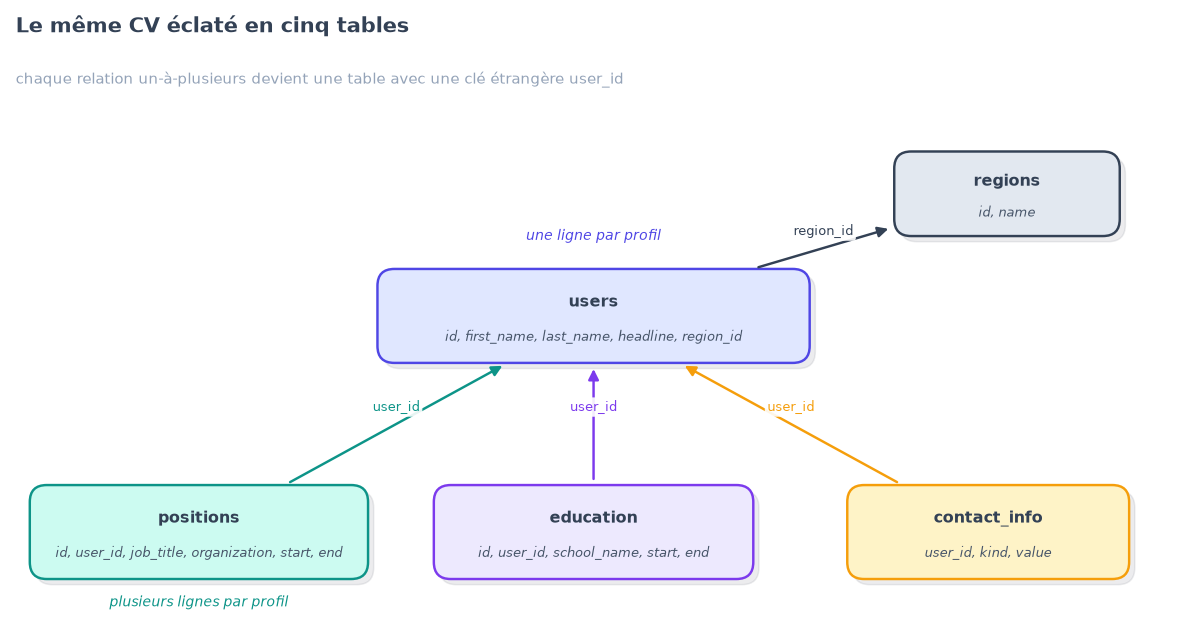

In [5]:
d = Diagram(12.5, 5.6, title="Le même CV éclaté en cinq tables",
            subtitle="chaque relation un-à-plusieurs devient une table avec une clé étrangère user_id")
d.box("users", 6.2, 3.3, "users", sub="id, first_name, last_name, headline, region_id", color=INDIGO, w=4.6, h=1.0)
d.box("pos", 2.0, 1.0, "positions", sub="id, user_id, job_title, organization, start, end", color=TEAL, w=3.6, h=1.0)
d.box("edu", 6.2, 1.0, "education", sub="id, user_id, school_name, start, end", color=VIOLET, w=3.4, h=1.0)
d.box("con", 10.4, 1.0, "contact_info", sub="user_id, kind, value", color=AMBER, w=3.0, h=1.0)
d.box("reg", 10.6, 4.6, "regions", sub="id, name", color=SLATE, w=2.4, h=0.9)
d.arrow("pos", "users", "user_id", color=TEAL)
d.arrow("edu", "users", "user_id", color=VIOLET)
d.arrow("con", "users", "user_id", color=AMBER)
d.arrow("users", "reg", "region_id", color=SLATE)
d.note(6.2, 4.15, "une ligne par profil", color=INDIGO)
d.note(2.0, 0.25, "plusieurs lignes par profil", color=TEAL)
d.show()

La **représentation document** garde l'arbre tel quel : un seul objet JSON contient les
listes de postes et de formations, et le dictionnaire des coordonnées. Elle est
directement sérialisable depuis nos objets Python :

In [6]:
from dataclasses import asdict
doc_ines = asdict(ines)
print(json.dumps(doc_ines, ensure_ascii=False, indent=2))

{
  "user_id": 42,
  "first_name": "Inès",
  "last_name": "Martin",
  "headline": "Architecte de données chez Datanet",
  "region_id": "fr:69",
  "positions": [
    {
      "job_title": "Architecte de données",
      "organization": "Datanet",
      "start": 2014,
      "end": null
    },
    {
      "job_title": "Ingénieure logiciel",
      "organization": "Novasoft",
      "start": 2009,
      "end": 2014
    }
  ],
  "education": [
    {
      "school_name": "INSA Lyon",
      "start": 2004,
      "end": 2009
    }
  ],
  "contact_info": {
    "blog": "https://ines.example",
    "github": "https://github.example/ines"
  }
}


Les relations un-à-plusieurs du profil dessinent un **arbre** : la racine (le profil),
des branches (les listes), des feuilles (les champs). Le document JSON rend cet arbre
explicite, quand le schéma relationnel le disperse dans plusieurs tables qu'il faudra
recoller. Dessinons cet arbre à partir du document lui-même.

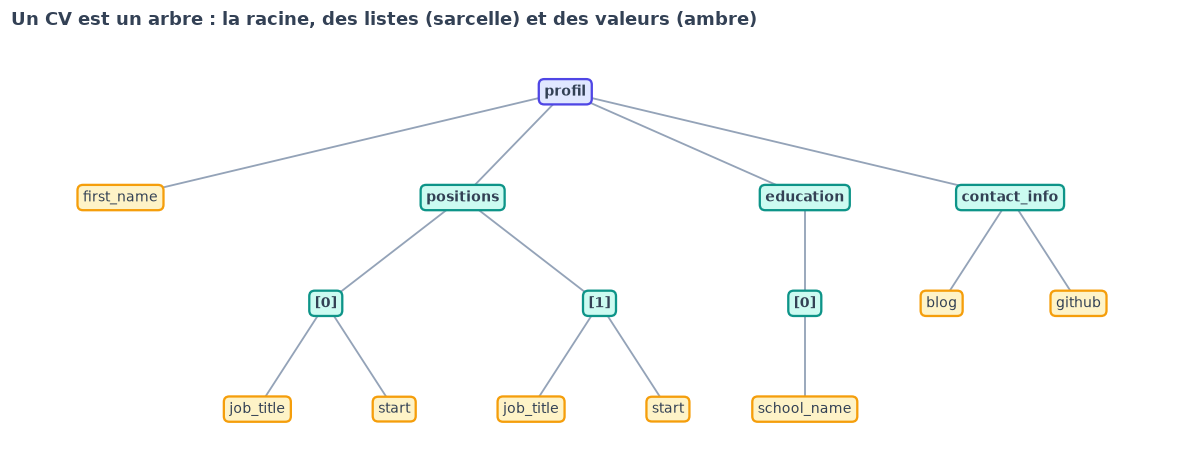

In [7]:
def tree_layout(doc, name="profil"):
    """Positions (x, profondeur) des nœuds d'un document JSON : feuilles espacées régulièrement."""
    nodes, edges, leaves = [], [], [0]
    def visit(key, val, depth, parent):
        idx = len(nodes)
        nodes.append([key, depth, None, isinstance(val, (dict, list))])
        if parent is not None:
            edges.append((parent, idx))
        children = list(val.items()) if isinstance(val, dict) else (
            [(f"[{i}]", v) for i, v in enumerate(val)] if isinstance(val, list) else [])
        if not children:
            nodes[idx][2] = leaves[0]; leaves[0] += 1
        else:
            xs = [visit(k, v, depth + 1, idx) for k, v in children]
            nodes[idx][2] = (min(xs) + max(xs)) / 2
        return nodes[idx][2]
    visit(name, doc, 0, None)
    return nodes, edges

small = {k: doc_ines[k] for k in ["first_name", "positions", "education", "contact_info"]}
small["positions"] = [{"job_title": p["job_title"][:12] + ".", "start": p["start"]} for p in small["positions"]]
small["education"] = [{"school_name": "INSA Lyon"}]
nodes, edges = tree_layout(small)
fig, ax = plt.subplots(figsize=(11, 4.4))
for a, b in edges:
    ax.plot([nodes[a][2], nodes[b][2]], [-nodes[a][1], -nodes[b][1]], color=GRAY, lw=1.2, zorder=1)
for key, depth, x, inner in nodes:
    col = INDIGO if depth == 0 else (TEAL if inner else AMBER)
    ax.text(x, -depth, key, ha="center", va="center", fontsize=9, color=SLATE, zorder=3,
            fontweight="bold" if inner else "normal",
            bbox=dict(boxstyle="round,pad=0.4", fc=LIGHT[col], ec=col, lw=1.5))
ax.set_axis_off(); ax.set_ylim(-3.5, 0.4); ax.set_xlim(-0.8, max(n[2] for n in nodes) + 0.8)
ax.set_title("Un CV est un arbre : la racine, des listes (sarcelle) et des valeurs (ambre)")
plt.tight_layout(); plt.show()

> **À retenir.** Le décalage objet-relationnel vient de ce que les objets de
> l'application sont imbriqués alors que les tables sont plates. Pour des données en
> forme d'**arbre de relations un-à-plusieurs**, comme un CV, le document JSON colle à la
> structure de l'application ; le schéma relationnel l'éclate en plusieurs tables.

## 4. Recomposer un CV : plusieurs requêtes, une jointure ou un document ?

Pour afficher un profil complet à partir du schéma relationnel, deux options : **une
requête par table** (quatre requêtes sur `users`, `positions`, `education`,
`contact_info`) ou **une jointure multiple** qui ramène tout en une fois. Avec le
modèle document, une seule lecture suffit. Comparons les trois sur un jeu de 5 000
profils synthétiques (`dm.make_profiles`), rangés dans les deux formes sur SQLite.

In [8]:
orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(5_000, seed=0, orgs=orgs)
con = sqlite3.connect(":memory:")
dm.create_relational(con, profiles, orgs)
dm.create_documents(con, profiles)
cc = dm.CountingConnection(con)

lignes = {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
          for t in ["users", "positions", "education", "contact_info", "profiles"]}
pd.DataFrame({"table": list(lignes), "lignes": list(lignes.values())})

,table,lignes
0,users,5000
1,positions,17284
2,education,7474
3,contact_info,7492
4,profiles,5000


Les trois méthodes de lecture (`get_profile_multi`, `get_profile_join`,
`get_profile_doc`) renvoient exactement le même dictionnaire ; vérifions-le, et comptons
pour chacune le nombre de requêtes et de lignes reçues.

In [9]:
rows = []
for uid in rng.choice(np.arange(1, 5001), 400, replace=False):
    uid = int(uid)
    res = []
    for meth, f in [("4 requêtes", dm.get_profile_multi), ("1 jointure multiple", dm.get_profile_join),
                    ("1 document", dm.get_profile_doc)]:
        cc.reset()
        res.append(f(cc, uid))
        rows.append({"méthode": meth, "uid": uid, "requêtes": cc.queries, "lignes": cc.rows})
    assert res[0] == res[1] == res[2] == profiles[uid - 1]
mesures = pd.DataFrame(rows)
mesures.groupby("méthode", sort=False)[["requêtes", "lignes"]].agg(["mean", "max"])

requêtes      lignes    
                        mean max    mean max
méthode                                     
4 requêtes               4.0   4   7.452  13
1 jointure multiple      1.0   1  10.658  54
1 document               1.0   1   1.000   1

La jointure multiple est séduisante (une seule requête), mais elle a un défaut caché :
les trois listes étant **indépendantes**, la jointure renvoie leur **produit
cartésien**. Un profil de 6 postes, 3 formations et 3 coordonnées produit
$6 \times 3 \times 3 = 54$ lignes pour 13 éléments utiles (l'en-tête et 12 éléments de
listes), qu'il faut ensuite
dédoublonner côté client. C'est la « jointure multiple désordonnée » que le livre
évoque.

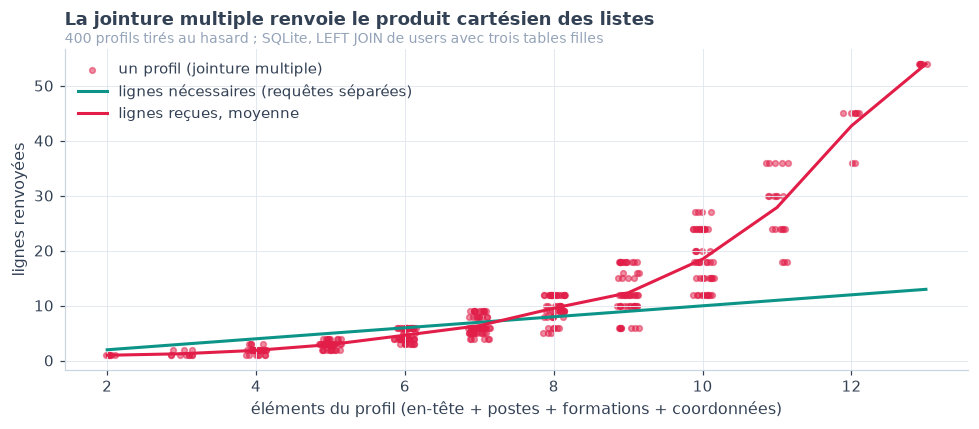

In [10]:
jn = mesures[mesures["méthode"] == "1 jointure multiple"].copy()
utiles = []
for uid in jn.uid:
    p = profiles[uid - 1]
    utiles.append(1 + len(p["positions"]) + len(p["education"]) + len(p["contact_info"]))
jn["éléments utiles"] = utiles
agg = jn.groupby("éléments utiles")["lignes"].agg(["mean", "max"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(jn["éléments utiles"] + rng.uniform(-0.15, 0.15, len(jn)), jn["lignes"], s=14, color=ROSE, alpha=0.5,
           label="un profil (jointure multiple)")
ax.plot(agg.index, agg.index, color=TEAL, lw=2, label="lignes nécessaires (requêtes séparées)")
ax.plot(agg.index, agg["mean"], color=ROSE, lw=2, label="lignes reçues, moyenne")
ax.set_xlabel("éléments du profil (en-tête + postes + formations + coordonnées)")
ax.set_ylabel("lignes renvoyées")
ax.set_title("La jointure multiple renvoie le produit cartésien des listes")
subtitle(ax, "400 profils tirés au hasard ; SQLite, LEFT JOIN de users avec trois tables filles")
ax.legend(); plt.tight_layout(); plt.show()

Côté temps, SQLite s'exécute ici **dans notre processus** : une requête ne coûte que
quelques microsecondes. Une vraie base est **distante**, et chaque requête paie un
aller-retour réseau (de 0,1 ms dans un même centre de données à plusieurs dizaines de
millisecondes entre continents). Le modèle `dm.round_trip_cost` additionne ces
allers-retours et le transfert des lignes ; appliquons-le aux mesures.

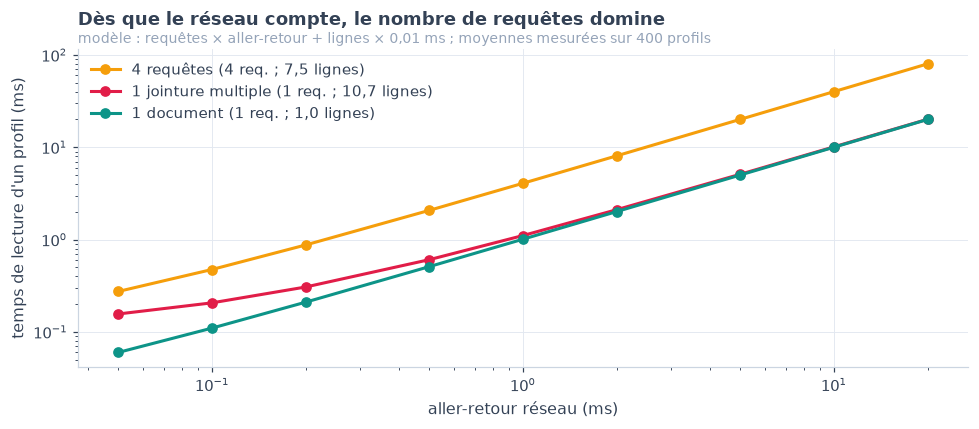

In [11]:
rtts = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20])
moy = mesures.groupby("méthode", sort=False)[["requêtes", "lignes"]].mean()
fig, ax = plt.subplots(figsize=(9, 4))
for (meth, r), col in zip(moy.iterrows(), [AMBER, ROSE, TEAL]):
    ax.plot(rtts, [dm.round_trip_cost(r["requêtes"], r["lignes"], rtt, per_row_ms=0.01) for rtt in rtts],
            marker="o", color=col, label=f"{meth} ({r['requêtes']:.0f} req. ; " + f"{r['lignes']:.1f}".replace(".", ",") + " lignes)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("aller-retour réseau (ms)"); ax.set_ylabel("temps de lecture d'un profil (ms)")
ax.set_title("Dès que le réseau compte, le nombre de requêtes domine")
subtitle(ax, "modèle : requêtes × aller-retour + lignes × 0,01 ms ; moyennes mesurées sur 400 profils")
ax.legend(); plt.tight_layout(); plt.show()

Les quatre requêtes séparées coûtent quatre allers-retours : quatre fois plus que le
document dès que le réseau dépasse quelques dixièmes de milliseconde. La jointure
multiple n'a qu'un aller-retour mais transporte nettement plus de lignes ; elle reste
compétitive tant que les listes sont courtes. Le document, lui, cumule les deux
avantages : **une requête, une ligne**.

> **À retenir.** Pour recomposer un arbre stocké en tables, on paie soit plusieurs
> allers-retours, soit une jointure multiple qui gonfle en produit cartésien. Le
> document ramène l'arbre entier en une lecture : c'est l'argument de **localité**.